R-squared: 0.9759036144578314
R-squared Percentage: 97.59036144578313 %
RMSE: 2.0
Predicted Marks for 6 Hours: 85.00000000000001


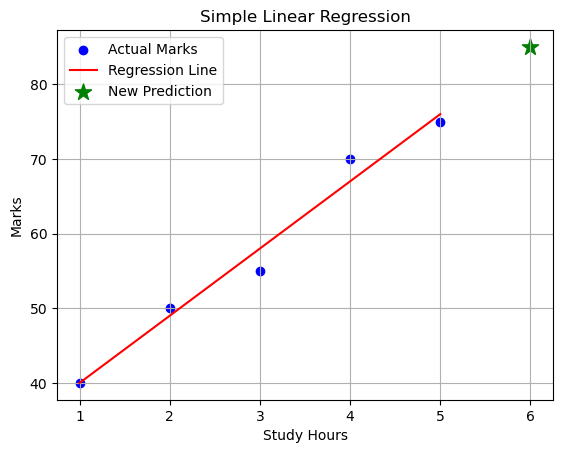

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Input data: Study Hours
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)

# Actual output: Marks
y = np.array([40, 50, 55, 70, 75])

# Create the model
model = LinearRegression()

# Train the model
model.fit(X, y)

# Predict marks for the original students
y_pred = model.predict(X)

# Calculate R-squared
r2 = r2_score(y, y_pred)

# Calculate RMSE
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

# Display evaluation results
print("R-squared:", r2)
print("R-squared Percentage:", r2 * 100, "%")
print("RMSE:", rmse)

# Predict marks for a new student
prediction = model.predict([[6]])
print("Predicted Marks for 6 Hours:", prediction[0])

# Plot actual data and regression line
plt.scatter(X, y, color="blue", label="Actual Marks")
plt.plot(X, y_pred, color="red", label="Regression Line")

# Show the new predicted point
plt.scatter(6, prediction[0], color="green",
            marker="*", s=150, label="New Prediction")

plt.xlabel("Study Hours")
plt.ylabel("Marks")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

Student Dataset:
   StudyHours  Attendance  Marks
0           1          40     18
1           2          20     17
2           3          60     25
3           4         100     33
4           5          80     32

Intercept: 10.0
Study Hours Coefficient: 2.0000000000000004
Attendance Coefficient: 0.14999999999999997

Regression Equation:
Marks = 10.00 + 2.00 * StudyHours + 0.15 * Attendance

Actual vs Predicted Marks:
   StudyHours  Attendance  Marks  PredictedMarks
0           1          40     18            18.0
1           2          20     17            17.0
2           3          60     25            25.0
3           4         100     33            33.0
4           5          80     32            32.0

New Student Details:
   StudyHours  Attendance
0           6          90

Predicted Marks: 35.5

R-squared: 1.0
R-squared Percentage: 100.0 %

Mean Squared Error: 0.0
RMSE: 0.0


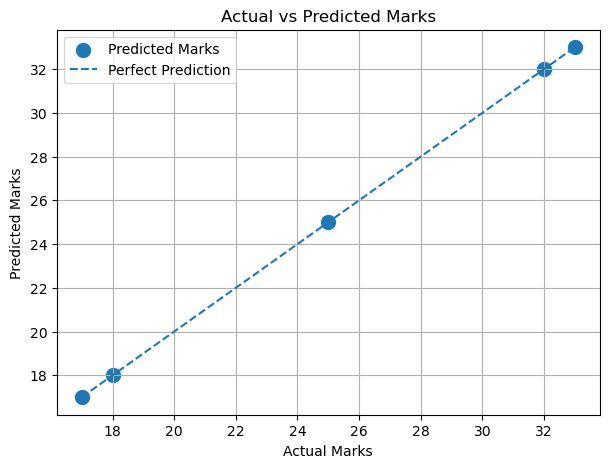

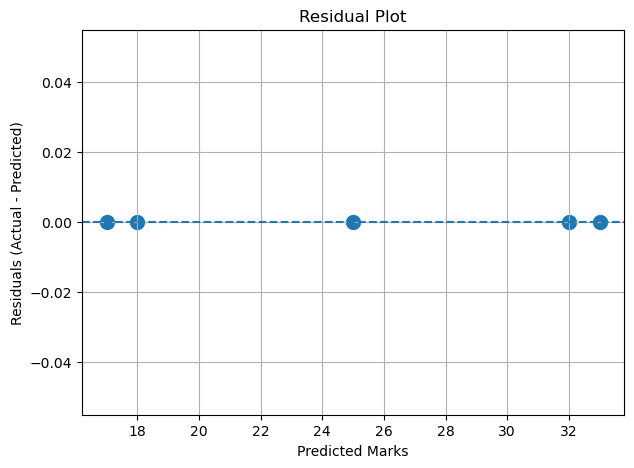

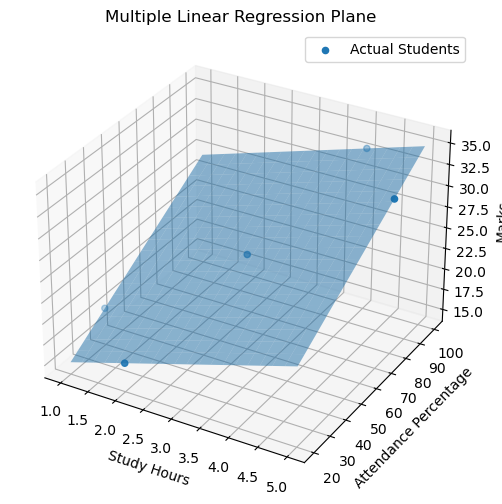

In [2]:

# MULTIPLE LINEAR REGRESSION

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error


# 2. Create Dataset
data = {
    'StudyHours': [1, 2, 3, 4, 5],
    'Attendance': [40, 20, 60, 100, 80],
    'Marks': [18, 17, 25, 33, 32]
}

df = pd.DataFrame(data)

print("Student Dataset:")
print(df)


# 3. Define Independent and Dependent Variables
X = df[['StudyHours', 'Attendance']]
y = df['Marks']


# 4. Create Multiple Linear Regression Model
model = LinearRegression()


# 5. Train the Model
model.fit(X, y)


# 6. Display Intercept and Coefficients
print("\nIntercept:", model.intercept_)
print("Study Hours Coefficient:", model.coef_[0])
print("Attendance Coefficient:", model.coef_[1])


# 7. Display Regression Equation
print("\nRegression Equation:")

print(
    f"Marks = {model.intercept_:.2f} + "
    f"{model.coef_[0]:.2f} * StudyHours + "
    f"{model.coef_[1]:.2f} * Attendance"
)


# 8. Predict Marks for All Students
y_pred = model.predict(X)

df['PredictedMarks'] = y_pred

print("\nActual vs Predicted Marks:")
print(df)


# 9. Predict Marks for a New Student
new_student = pd.DataFrame({
    'StudyHours': [6],
    'Attendance': [90]
})

new_prediction = model.predict(new_student)

print("\nNew Student Details:")
print(new_student)

print("\nPredicted Marks:", new_prediction[0])


# 10. Calculate R-squared
r2 = r2_score(y, y_pred)

print("\nR-squared:", r2)
print("R-squared Percentage:", r2 * 100, "%")


# 11. Calculate MSE and RMSE
mse = mean_squared_error(y, y_pred)
rmse = np.sqrt(mse)

print("\nMean Squared Error:", mse)
print("RMSE:", rmse)


# 12. Visualization 1: Actual vs Predicted Marks
plt.figure(figsize=(7, 5))

plt.scatter(y, y_pred, s=100, label="Predicted Marks")

plt.plot(
    [y.min(), y.max()],
    [y.min(), y.max()],
    linestyle='--',
    label="Perfect Prediction"
)

plt.xlabel("Actual Marks")
plt.ylabel("Predicted Marks")
plt.title("Actual vs Predicted Marks")

plt.legend()
plt.grid()
plt.show()


# 13. Visualization 2: Residual Plot
residuals = y - y_pred

plt.figure(figsize=(7, 5))

plt.scatter(y_pred, residuals, s=100)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Marks")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot")

plt.grid()
plt.show()


# 14. Visualization 3: Regression Plane
fig = plt.figure(figsize=(8, 6))

ax = fig.add_subplot(111, projection='3d')

study_range = np.linspace(1, 5, 20)
attendance_range = np.linspace(20, 100, 20)

study_grid, attendance_grid = np.meshgrid(
    study_range, attendance_range
)

plane_input = pd.DataFrame({
    'StudyHours': study_grid.ravel(),
    'Attendance': attendance_grid.ravel()
})

marks_grid = model.predict(plane_input).reshape(study_grid.shape)

ax.plot_surface(
    study_grid,
    attendance_grid,
    marks_grid,
    alpha=0.5
)

ax.scatter(
    df['StudyHours'],
    df['Attendance'],
    df['Marks'],
    label='Actual Students'
)

ax.set_xlabel("Study Hours")
ax.set_ylabel("Attendance Percentage")
ax.set_zlabel("Marks")

ax.set_title("Multiple Linear Regression Plane")

ax.legend()
plt.show()
